# Ejercicio practico
![logo itq](img/ITQ.png)
**nombre:** Belen Campos

**fecha:** 05-11-2026

**link del repositorio:** <a href="https://github.com/mabelcampos14/fundamentosMachineLearnigNocturno26-27/blob/main/programa1normalizacion.ipynb">link repositorio<a/>

Outliers: Un outlier o valor atípico es una observación que se encuentra a una distancia anormal del resto de los valores en un conjunto de datos, ya sea por ser extremadamente alto o bajo en comparación con la media o la mediana del grupo.. No siempre son errores; pueden reflejar fenómenos inusuales, errores de medición o variabilidad natural.

In [10]:
import pandas as pd
import numpy as np 
from scipy import stats
from sklearn.covariance import EllipticEnvelope
import matplotlib.pyplot as plt

In [19]:
#Carga dedatos.
df =pd.read_csv("dataset/outliers.csv")
print(df)

            a         b
0    0.149014 -0.041479
1    0.194307  0.456909
2   -0.070246 -0.070241
3    0.473764  0.230230
4   -0.140842  0.162768
..        ...       ...
195 -5.114441  0.646251
196  5.631630  0.277174
197  1.552784  2.348984
198 -0.545507  1.530697
199  1.011772  4.813896

[200 rows x 2 columns]


Detección de valores atípicos con EllipticEnvelope

1.
Configuramos el modelo. contamination=0.25 indica que el modelo usará una proporción esperada del 25 % de valores atípicos para fijar su umbral. random_state=42 ayuda a reproducir el resultado.

2. Ajustamos el modelo. fit(df) estima una región elíptica a partir de las variables numéricas del dataset.

3.  Clasificamos las filas. predict(df) aplica el modelo al mismo dataset y devuelve un arreglo con una etiqueta por fila. El valor 1 indica una observación normal y indica un posible valor atípico.

5. Ubicamos y contamos los casos. -1 np.where(df_outliers == -1)[0] obtiene las posiciones de las filas marcadas, empezando desde cero. len(pos_outliers) devuelve cuántas filas se marcaron en total.

In [20]:
#Entrenamos un objetodetipoEllipticEnvelope 
algorithm =EllipticEnvelope(support_fraction=None,contamination=0.25,
random_state=42) 
outlier_method= algorithm.fit(df)
#Aplicamos elmétododedeteccióndeoutliersentrenadosobrenuestodataset␣
#devuelveunanuevacolumna 
df_outliers= outlier_method.predict(df)
print(df_outliers)
# # Determinar la posición de los outliers
pos_outliers = np.where(df_outliers==-1)[0]
print('\nOutliers en la posición: \n', pos_outliers) 
# # Determinar el número de outliers
print('\nNúmero de outliers: \n', len(pos_outliers))     

[ 1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1]

Outliers en la posición: 
 [150 151 152 153 154 155 156 157 158 159 160 161 162 163 164 165 166 167
 168 169 170 171 172 173 174 175 176 177 178 179 180 181 182 183 184 185
 186 187 188 189 190 191 192 193 194 195 196 197 198 199]

Número de outliers: 
 50


Función para detectar valores atípicos

Definimosfind_outliers(df, algorithm) para aplicar el mismo procedimiento de detección a distintos modelos que admitan fit() y predict() .

. df es la tabla con los datos que queremos analizar. 

. algorithm es el modelo de detección que vamos a utilizar.

Primero, algorithm.fit(df) ajusta el modelo con los datos. Luego, clasifica cada fila del mismo conjunto. La etiqueta predict(df) 1 indica una observación normal y -1 indica un posible valor atípico.

Con np.where(df_outliers == -1)[0] obtenemos las posiciones de las filas marcadas, empezando desde cero. La función muestra las etiquetas, las posiciones y el total de casos detectados.

Al final, return devuelve dos arreglos: df_outliers , con una etiqueta por fila, y pos_outliers , con las posiciones de los posibles valores atípicos. La detección se ejecuta cuando llamamos a la función.

In [21]:
# Definimos una función que, dado un determinado "df" y un "algorithm",␣
#devuelva la matriz y la posición de outliers
def find_outliers(df, algorithm):
    outlier_method = algorithm.fit(df)
    #Aplicacmos el método de detección de outliers entrenado sobre nuestro␣dataset
    df_outliers = outlier_method.predict(df) 
    print(df_outliers) 
    #determinamos la posicion de los outliers 
    pos_outliers=np.where(df_outliers==-1)[0]
    print('\nOutliers en la posición :\n', pos_outliers) 
    #Determinamos el número de outliers 
    print('\nNúmero de outliers: \n', len(pos_outliers)) 
    return df_outliers, pos_outliers

Otros métodos para detectar valores atípicos 

En esta celda importamos y configuramos tres modelos de observaciones atípicas de distintas maneras.

Modelo ¿Cómo detecta valores atípicos? 

| scikit-learn que identifican IsolationForest | Usa árboles que dividen los datos al azar. Las observaciones que se aíslan con pocas divisiones tienden a ser atípicas. | | OneClassSVM | Aprende una frontera que delimita la región de los datos habituales. Las observaciones que quedan fuera se consideran posibles valores atípicos. | | LocalOutlierFactor | Compara la densidad alrededor de cada observación con la de sus vecinos. Aquí utiliza 10 vecinos y la distancia euclidiana. | 

En esta ejecución aplicamos únicamente IsolationForest mediante find_outliers(df, IF) . La función devuelve una etiqueta por fila y las posiciones de lasobservaciones marcadas como atípicas. Finalmente, observaciones se detectaron.

In [22]:
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
IF = IsolationForest(max_samples='auto', random_state=42) 
OC_SVM = OneClassSVM(kernel="poly", degree=1, gamma="auto")
LOF = LocalOutlierFactor(n_neighbors=10, algorithm="auto", metric="euclidean") 
df_outliers, pos_outliers = find_outliers(df, IF)
print(len(pos_outliers))

[ 1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1  1 -1]

Outliers en la posición :
 [150 151 152 153 154 155 156 157 158 159 160 161 162 163 165 166 167 168
 169 170 171 172 173 174 175 176 177 178 179 180 181 182 183 184 185 186
 187 188 189 190 191 192 193 194 195 196 197 199]

Número de outliers: 
 48
48


In [23]:
df.head(10)

,a,b
0,0.149014,-0.041479
1,0.194307,0.456909
2,-0.070246,-0.070241
3,0.473764,0.230230
4,-0.140842,0.162768
5,-0.139025,-0.139719
6,0.072589,-0.573984
7,-0.517475,-0.168686
8,-0.303849,0.094274
9,-0.272407,-0.423691


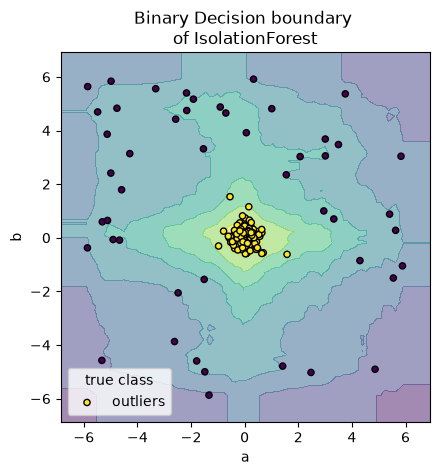

In [24]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay 
disp = DecisionBoundaryDisplay.from_estimator(
    IF, 
    df, 
    response_method = "decision_function",
    alpha=0.5, 
) 
disp.ax_.scatter(df.a,df.b,c=df_outliers,s=20,edgecolor="k")
disp.ax_.set_title("Binary Decision boundary \nof IsolationForest")
plt.axis("square") 
plt.legend(labels=["outliers","inliers"], title="true class") 
plt.show()

In [25]:
# Eliminamos los outliers 
new_df = df[df_outliers==1] 
print(new_df)

            a         b
0    0.149014 -0.041479
1    0.194307  0.456909
2   -0.070246 -0.070241
3    0.473764  0.230230
4   -0.140842  0.162768
..        ...       ...
147  0.107105 -0.207873
148  0.269880  0.092190
149  0.243859  0.188889
164  1.582047 -0.618654
198 -0.545507  1.530697

[152 rows x 2 columns]


limiteinferior:  -1.0853060827395105
limitesuperior:  1.0119554520872196
Posiciónde outliers: [150 153 154 157 159 160 162 165 168 169 171 172 174 175 177 178 181 184
 185 186 187 190 191 192 193 195 151 152 155 156 161 163 164 166 167 173
 176 179 180 182 188 189 196 197]
Númerodeoutliers: 44


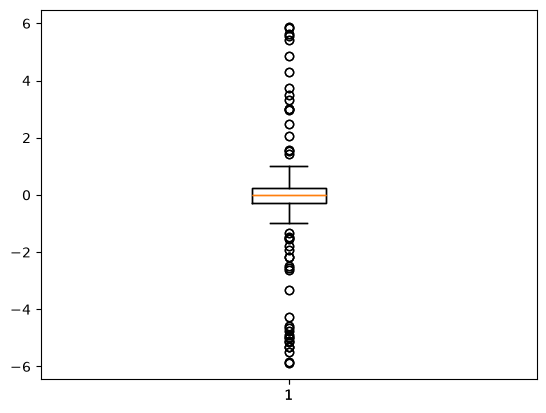

In [26]:
#Seleccionamos elatributoquevamosamedir
a =df['a']
#Seleccionamos los umbralesapartirdeloscualesvamosaconsideraroutliers
Q1 =stats.scoreatpercentile(a, 25)
Q3 =stats.scoreatpercentile(a, 75) 
RIC= Q3-Q1 
li =Q1-1.5*RIC#xmin 
ls =Q3 + 1.5*RIC#xmax
#Observamos los límitesinferiorysuperior 
print('limiteinferior: ',li)
print('limitesuperior: ',ls)
#Buscamoslaposicióndelosoutliers
pos_i =np.where(a<li)[0] 
pos_s =np.where(a>ls)[0] 
pos_outliers =np.concatenate((pos_i,pos_s)) 
print('Posiciónde outliers:',pos_outliers) 
print('Númerodeoutliers:',len(pos_outliers))
#Dibujamos eldiagrama decajaybigotes 
prop= plt.boxplot(a) 
plt.boxplot(a) 
plt.show()

In [27]:
#Definir una función que, dada una columna de un dataframe, devuelva la␣
#posición de los outliers según el método box plot
def find_limits_BP(variable): 
    Q1 = stats.scoreatpercentile(variable, 25) 
    Q3 = stats.scoreatpercentile(variable, 75) 
    RIC = Q3 - Q1  
    
    li = Q1 - 1.5 * RIC 
    ls = Q3 + 1.5 * RIC  
    
    pos_i = np.where(variable < li)[0]  
    pos_s = np.where(variable > ls)[0]  
    
    pos_outliers = np.concatenate((pos_i, pos_s))    
    return pos_outliers

In [28]:
# Creamos un bucle for que estime los valores outliers de cada atributo
headers = df.columns # nombre de los atributos del CSV 
pos_outliers = [] 
for i in range(len(headers)): 
    variable = df[headers[i]] # Atributo 'x'  
    pos_out = np.expand_dims(find_limits_BP(variable), axis=1) # Llamamos a la␣ 
#función que hemos creado 
pos_outliers.append(pos_out) # Lo añadimos en una lista
# Concatenamos todas las posiciones de outliers
po = np.vstack(pos_outliers) 
# Vemos las posiciones de todos los outliers 
pos_out = np.unique(po) 
print('Posiciones de outliers: ', pos_out)

Posiciones de outliers:  [104 150 151 152 153 154 156 157 158 159 160 161 162 165 166 167 170 171
 172 173 174 175 176 177 178 179 180 181 183 186 187 189 190 191 192 193
 194 197 198 199]


In [29]:
# Observamos el número de outliers 
print('Numero de outliers: ', len(pos_out))

Numero de outliers:  40
